In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as mticker


In [ ]:

# 1. Define file paths 
path_casualties = './Dataset/dft-road-casualty-statistics-casualty-last-5-years.csv'
path_collisions = './Dataset/dft-road-casualty-statistics-collision-last-5-years.csv'
path_vehicles = './Dataset/dft-road-casualty-statistics-vehicle-last-5-years.csv'

# 2. Load the datasets (low_memory=False handles mixed types in large columns)
print("Loading files...")
collisions_df = pd.read_csv(path_collisions, low_memory=False)
vehicles_df = pd.read_csv(path_vehicles, low_memory=False)
casualties_df = pd.read_csv(path_casualties, low_memory=False)

print(f"Collisions shape: {collisions_df.shape}")
print(f"Vehicles shape: {vehicles_df.shape}")
print(f"Casualties shape: {casualties_df.shape}")

In [25]:
# information about the datasets
datasets = {
    "Collisions": collisions_df,
    "Vehicles": vehicles_df,
    "Casualties": casualties_df
}

for name, df in datasets.items() if hasattr(datasets, 'items') else datasets.items():
    print(f"\n{'='*20} DATASET: {name} {'='*20}")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

    # Missing values summary
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct})
    missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Percentage (%)', ascending=False)

    if not missing_df.empty:
        print("\nColumns with Missing Values:")
        print(missing_df.head(10)) # Print top 10 missing columns
    else:
        print("\nNo missing values found!")

    print("-" * 50)


==================== DATASET: Collisions ====================
Shape: 513801 rows, 44 columns

Columns with Missing Values:
                        Missing Count  Missing Percentage (%)
location_easting_osgr              53                0.010315
location_northing_osgr             53                0.010315
longitude                          53                0.010315
latitude                           53                0.010315
--------------------------------------------------

==================== DATASET: Vehicles ====================
Shape: 937265 rows, 32 columns

No missing values found!
--------------------------------------------------

==================== DATASET: Casualties ====================
Shape: 652821 rows, 24 columns

No missing values found!
--------------------------------------------------


Finding records with -1 values => indicate missing or out of range values

In [26]:


# Group your dataframes in a dictionary
datasets = {
    "Collisions": collisions_df,
    "Vehicles": vehicles_df,
    "Casualties": casualties_df
}

print("=== AUTOMATED -1 VALUE SCANNER ACROSS ALL DATASETS ===")

for name, df in datasets.items():
    print(f"\n{'='*25} DATASET: {name} {'='*25}")
    
    missing_data = []
    
    for col in df.columns:
        # Count rows where the value is explicitly -1
        count_minus_one = (df[col] == -1).sum()
        
        if count_minus_one > 0:
            pct = (count_minus_one / len(df)) * 100
            missing_data.append({
                'Column': col,
                '-1 Count': count_minus_one,
                'Percentage (%)': round(pct, 2)
            })
            
    if missing_data:
        # Convert to a DataFrame to sort from highest missing count to lowest
        missing_df = pd.DataFrame(missing_data).sort_values(by='-1 Count', ascending=False)
        
        # Print as a nice table format
        print(f"{'Column Name':<45} | {'-1 Count':<12} | {'Percentage (%)':<15}")
        print("-" * 78)
        for _, row in missing_df.iterrows():
            print(f"{row['Column']:<45} | {row['-1 Count']:<12} | {row['Percentage (%)']:<15}%")
    else:
        print("No -1 values found in this dataset!")
        
    print("=" * 78)

=== AUTOMATED -1 VALUE SCANNER ACROSS ALL DATASETS ===

========================= DATASET: Collisions =========================
Column Name                                   | -1 Count     | Percentage (%) 
------------------------------------------------------------------------------
local_authority_district                      | 513607       | 99.96          %
junction_control                              | 217897       | 42.41          %
enhanced_severity_collision                   | 204752       | 39.85          %
second_road_number                            | 178098       | 34.66          %
special_conditions_at_site                    | 151370       | 29.46          %
carriageway_hazards_historic                  | 151367       | 29.46          %
pedestrian_crossing_human_control_historic    | 150889       | 29.37          %
pedestrian_crossing_physical_facilities_historic | 150860       | 29.36          %
junction_detail_historic                      | 147476       | 28.7    

Data Preprocessing

In [27]:
# since missing values are very very less => drop that records
# Check shape before dropping
print(f"Collisions shape BEFORE dropping: {collisions_df.shape}")

# Drop rows where latitude or longitude is missing
collisions_df = collisions_df.dropna(subset=['latitude', 'longitude', 'location_easting_osgr', 'location_northing_osgr'])

# Check shape after dropping (should be exactly 2 rows less: 101,523)
print(f"Collisions shape AFTER dropping:  {collisions_df.shape}")

# Final sanity check for missing values across all datasets
print("\n--- Post-Cleaning Missing Value Check ---")
print("Collisions missing:", collisions_df[['latitude', 'longitude']].isnull().sum().sum())
print("Vehicles missing:   ", vehicles_df.isnull().sum().sum())
print("Casualties missing: ", casualties_df.isnull().sum().sum())

Collisions shape BEFORE dropping: (513801, 44)
Collisions shape AFTER dropping:  (513748, 44)

--- Post-Cleaning Missing Value Check ---
Collisions missing: 0
Vehicles missing:    0
Casualties missing:  0


In [28]:
# 1. Drop columns with excessively high missingness / unrecorded -1 values (> 30%)
cols_to_drop_collisions = [
    'local_authority_district', 'junction_control', 'enhanced_severity_collision', 
    'second_road_number', 'special_conditions_at_site', 'carriageway_hazards_historic', 
    'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 
    'junction_detail_historic'
]
cols_to_drop_vehicles = [
    'driver_distance_banding', 'age_of_vehicle', 'vehicle_manoeuvre_historic', 
    'vehicle_location_restricted_lane_historic', 'journey_purpose_of_driver_historic', 
    'engine_capacity_cc', 'propulsion_code', 'driver_imd_decile'
]
cols_to_drop_casualties = [
    'casualty_distance_banding', 'enhanced_casualty_severity'
]

collisions_df.drop(columns=[c for c in cols_to_drop_collisions if c in collisions_df.columns], inplace=True)
vehicles_df.drop(columns=[c for c in cols_to_drop_vehicles if c in vehicles_df.columns], inplace=True)
casualties_df.drop(columns=[c for c in cols_to_drop_casualties if c in casualties_df.columns], inplace=True)


# 2. Drop rows for negligible/rare missing values (< 1%) in critical variables
collisions_df = collisions_df[collisions_df['speed_limit'] != -1]
collisions_df = collisions_df[collisions_df['weather_conditions'] != -1]
collisions_df = collisions_df[collisions_df['light_conditions'] != -1]


# 3. Map remaining categorical -1 values to 'Unknown' to preserve data size for pattern mining
for col in collisions_df.select_dtypes(include=['int64', 'float64']).columns:
    collisions_df[col] = collisions_df[col].replace(-1, 'Unknown')

for col in vehicles_df.select_dtypes(include=['int64', 'float64']).columns:
    vehicles_df[col] = vehicles_df[col].replace(-1, 'Unknown')

for col in casualties_df.select_dtypes(include=['int64', 'float64']).columns:
    casualties_df[col] = casualties_df[col].replace(-1, 'Unknown')

print("Categorical preprocessing and -1 handling completed successfully.")

C:\Users\user\AppData\Local\Temp\ipykernel_5344\1155666019.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  collisions_df.drop(columns=[c for c in cols_to_drop_collisions if c in collisions_df.columns], inplace=True)


Categorical preprocessing and -1 handling completed successfully.


In [29]:
# Print columns for Collisions dataset
print("--- Collisions Dataset Columns ---")
print(collisions_df.columns.tolist())
print(f"Total columns: {len(collisions_df.columns)}\n")

# Print columns for Vehicles dataset
print("--- Vehicles Dataset Columns ---")
print(vehicles_df.columns.tolist())
print(f"Total columns: {len(vehicles_df.columns)}\n")

# Print columns for Casualties dataset
print("--- Casualties Dataset Columns ---")
print(casualties_df.columns.tolist())
print(f"Total columns: {len(casualties_df.columns)}")

--- Collisions Dataset Columns ---
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail', 'second_road_class', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'collision_injury_based', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight']
Total columns: 35

--- Vehicles Dataset Columns ---
['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 've

## EDA on Individual Datasets

1. Collisions Dataset EDA



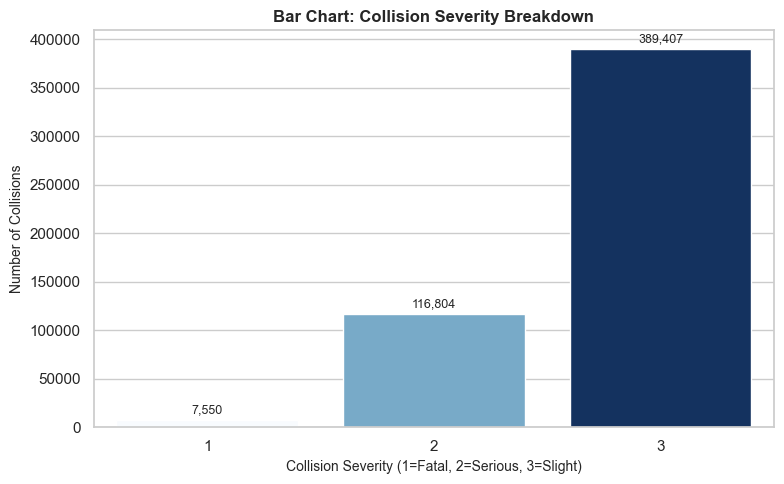

In [8]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

ax = sns.countplot(x='collision_severity', data=collisions_df, hue='collision_severity', palette='Blues', legend=False, order=[1, 2, 3])
plt.title('Bar Chart: Collision Severity Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Number of Collisions', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# Reveals a severe class imbalance where "Slight" accidents overwhelmingly dominate the dataset, while "Serious" and "Fatal" incidents represent a small fraction.

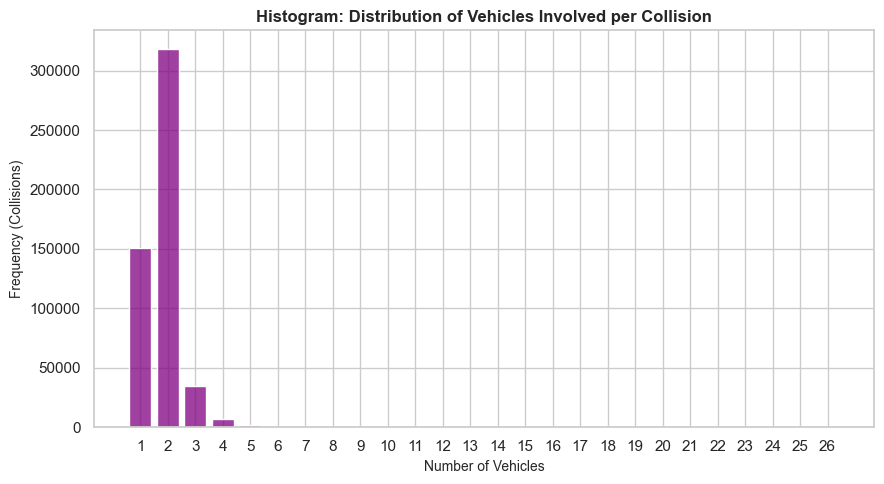

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(collisions_df['number_of_vehicles'], discrete=True, color='purple', shrink=0.8)
plt.title('Histogram: Distribution of Vehicles Involved per Collision', fontsize=12, fontweight='bold')
plt.xlabel('Number of Vehicles', fontsize=10)
plt.ylabel('Frequency (Collisions)', fontsize=10)

# Fix x-axis ticks to only show whole numbers based on the actual data range
max_vehicles = int(collisions_df['number_of_vehicles'].max())
plt.xticks(range(1, max_vehicles + 1))

plt.tight_layout()
plt.show(

)

# Purpose: To examine the structural complexity of accidents by checking whether crashes involve single vehicles or multi-vehicle chains.

# Inference: Demonstrates that the vast majority of collisions involve either 1 or 2 vehicles, indicating that most road incidents stem from single-vehicle driver errors or two-car interactions rather than massive multi-vehicle pileups.

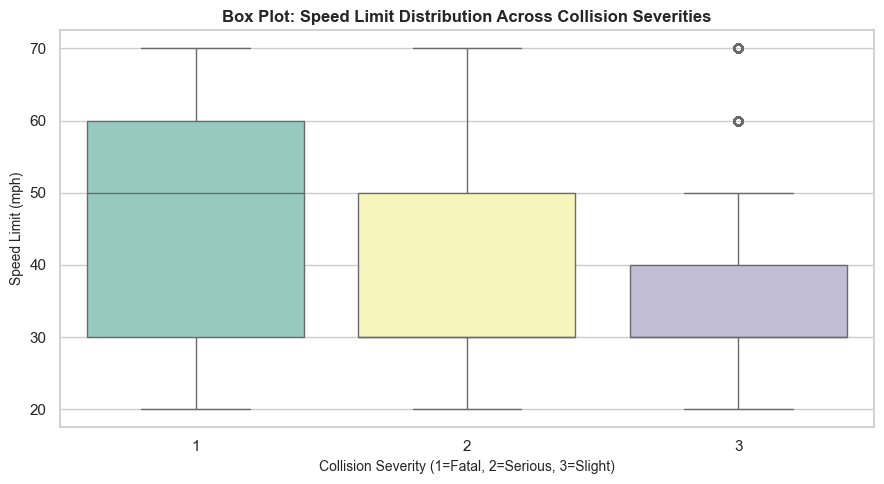

In [10]:
plt.figure(figsize=(9, 5))

sns.boxplot(x='collision_severity', y='speed_limit', data=collisions_df, palette='Set3', order=[1, 2, 3], hue='collision_severity', legend=False)
plt.title('Box Plot: Speed Limit Distribution Across Collision Severities', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Speed Limit (mph)', fontsize=10)

plt.tight_layout()
plt.show()

# Highlights that fatal and serious accidents frequently map to higher-speed zones (such as rural 50–60 mph roads), whereas slight accidents cluster heavily in urban 30 mph zones, confirming speed as a primary risk factor.

2. Vehicle Dataset EDA

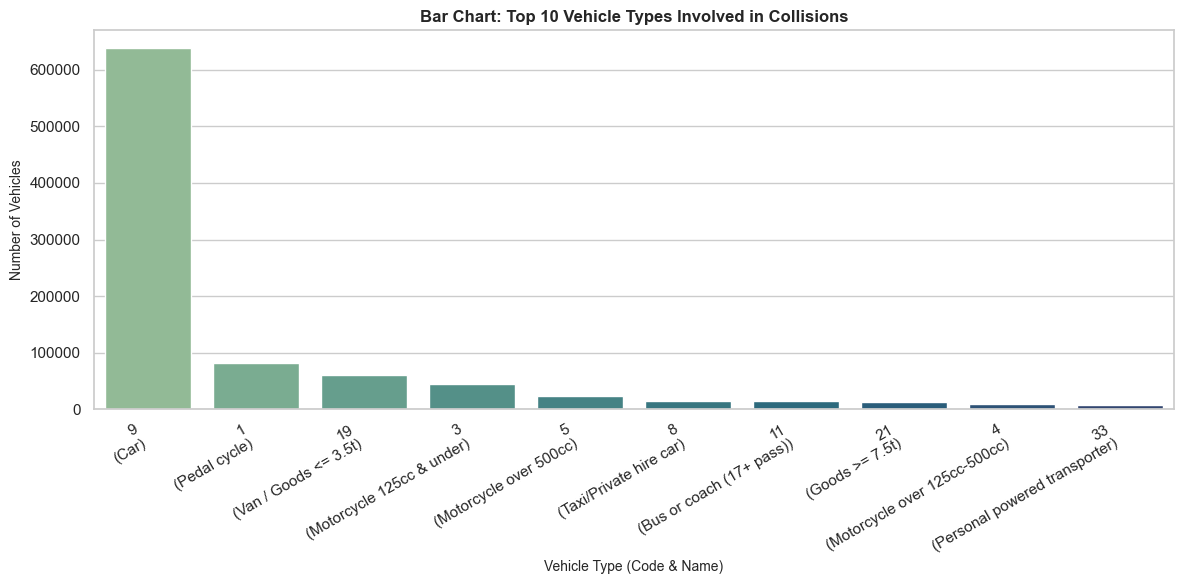

In [ ]:
# Mapping vehicle type codes to descriptive text labels
vehicle_mapping = {
    1: 'Pedal cycle',
    2: 'Motorcycle 50cc & under',
    3: 'Motorcycle 125cc & under',
    4: 'Motorcycle over 125cc-500cc',
    5: 'Motorcycle over 500cc',
    8: 'Taxi/Private hire car',
    9: 'Car',
    10: 'Minibus (8-16 pass)',
    11: 'Bus or coach (17+ pass)',
    16: 'Ridden horse',
    17: 'Agricultural vehicle',
    18: 'Tram',
    19: 'Van / Goods <= 3.5t',
    20: 'Goods > 3.5t & < 7.5t',
    21: 'Goods >= 7.5t',
    22: 'Mobility scooter',
    23: 'Electric motorcycle',
    33: 'Personal powered transporter',
    90: 'Other vehicle',
    97: 'Motorcycle - unknown cc',
    98: 'Goods vehicle - unknown weight',
    99: 'Unknown vehicle type',
    103: 'Motorcycle - Scooter (1979-1998)',
    104: 'Motorcycle (1979-1998)',
    105: 'Motorcycle - Combination (1979-1998)',
    106: 'Motorcycle over 125cc (1999-2004)',
    108: 'Taxi (excl. private hire) (1979-2004)',
    109: 'Car (incl. private hire) (1979-2004)',
    110: 'Minibus/Motor caravan (1979-1998)',
    113: 'Goods over 3.5 tonnes (1979-1998)'
}

plt.figure(figsize=(12, 6))

# Top 10 vehicle types
top_vehicles = vehicles_df['vehicle_type'].value_counts().head(10).reset_index()
top_vehicles.columns = ['vehicle_type', 'count']

# Map numeric codes to labels for display clarity
top_vehicles['vehicle_label'] = top_vehicles['vehicle_type'].map(
    lambda x: f"{x}\n({vehicle_mapping.get(x, 'Unknown')})"
)

ax = sns.barplot(
    data=top_vehicles, 
    x='vehicle_label', 
    y='count', 
    palette='crest', 
    hue='vehicle_label', 
    legend=False
)

plt.title('Bar Chart: Top 10 Vehicle Types Involved in Collisions', fontsize=12, fontweight='bold')
plt.xlabel('Vehicle Type (Code & Name)', fontsize=10)
plt.ylabel('Number of Vehicles', fontsize=10)

# Rotate X-axis labels for better legibility
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

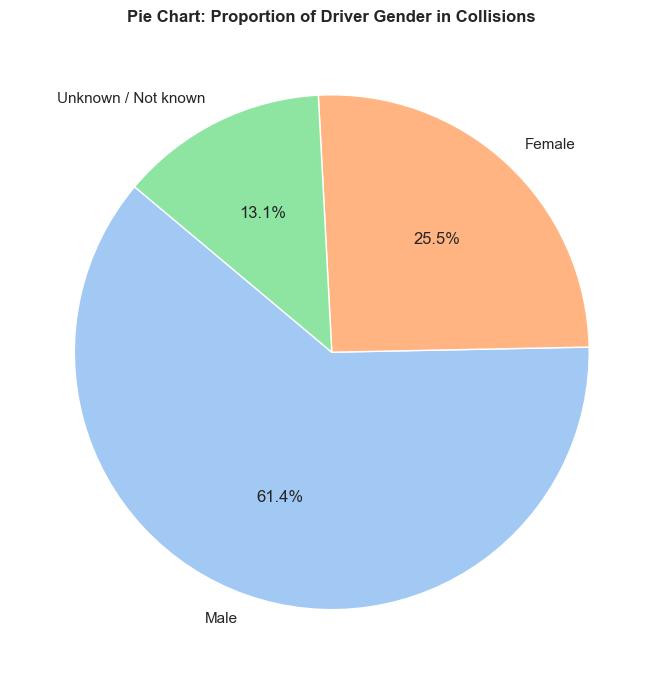

In [ ]:
# Mapping gender codes to human-readable labels 
# (Code 3 and any unmapped/missing codes are grouped under 'Unknown / Not known')
gender_mapping = {
    1: 'Male',
    2: 'Female',
    3: 'Unknown / Not known'
}

plt.figure(figsize=(7, 7))

# Filter out invalid placeholder codes like -1
filtered_df = vehicles_df[vehicles_df['sex_of_driver'] != -1].copy()

# Map numeric codes to descriptive labels, filling any missing mappings as 'Unknown'
filtered_df['gender_label'] = filtered_df['sex_of_driver'].map(gender_mapping).fillna('Unknown / Not known')

# Count occurrences of each category
gender_counts = filtered_df['gender_label'].value_counts()

# Plotting the pie chart
plt.pie(
    gender_counts, 
    labels=gender_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)

plt.title('Pie Chart: Proportion of Driver Gender in Collisions', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

3. Casualties Dataset EDA


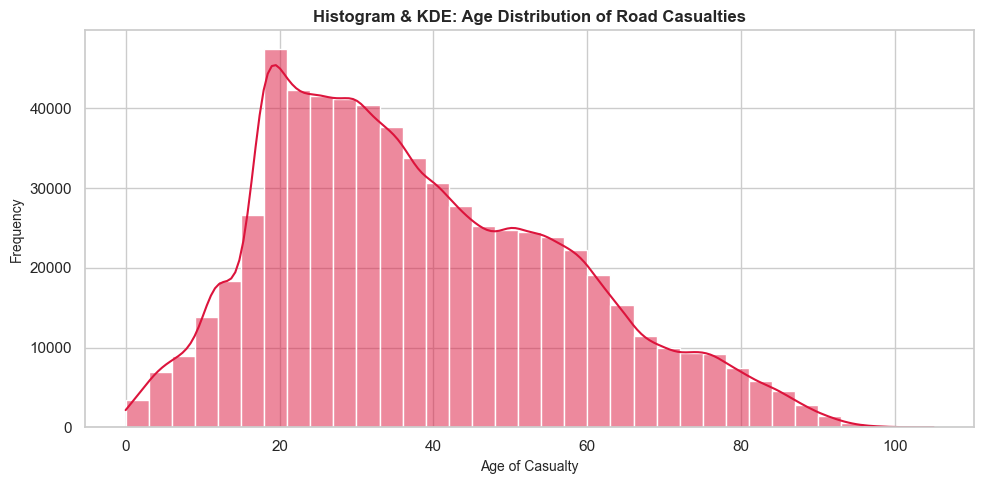

In [ ]:
plt.figure(figsize=(10, 5))

# Convert column to numeric, turning strings like "Unknown" into NaN, then drop NaNs
age_data = pd.to_numeric(casualties_df['age_of_casualty'], errors='coerce').dropna()

sns.histplot(age_data, bins=35, kde=True, color='crimson')
plt.title('Histogram & KDE: Age Distribution of Road Casualties', fontsize=12, fontweight='bold')
plt.xlabel('Age of Casualty', fontsize=10)
plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

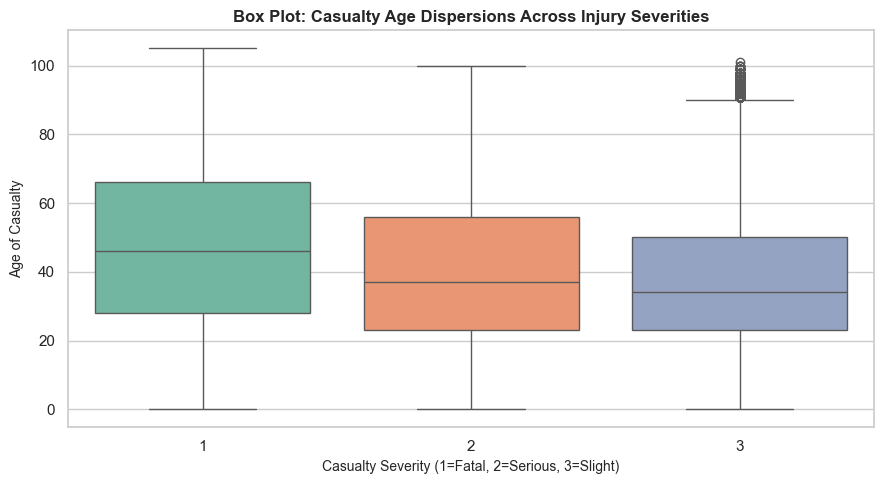

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure age of casualty is numeric (coercing any text like 'Unknown' to NaN)
casualties_df['age_of_casualty'] = pd.to_numeric(casualties_df['age_of_casualty'], errors='coerce')

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=casualties_df, 
    x='casualty_severity', 
    y='age_of_casualty', 
    palette='Set2', 
    order=[1, 2, 3], 
    hue='casualty_severity', 
    legend=False
)

plt.title('Box Plot: Casualty Age Dispersions Across Injury Severities', fontsize=12, fontweight='bold')
plt.xlabel('Casualty Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Age of Casualty', fontsize=10)

plt.tight_layout()
plt.show()

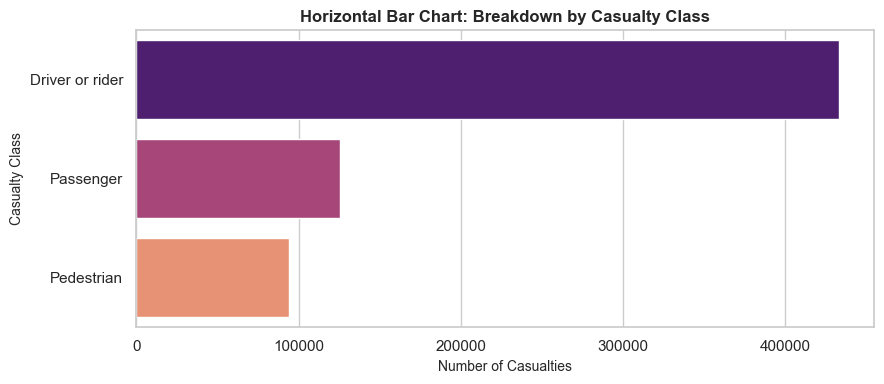

In [24]:
# Mapping casualty class codes to descriptive labels
class_mapping = {
    1: 'Driver or rider',
    2: 'Passenger',
    3: 'Pedestrian'
}

plt.figure(figsize=(9, 4))

# Count occurrences and map labels
class_counts = casualties_df['casualty_class'].value_counts().reset_index()
class_counts.columns = ['casualty_class', 'count']
class_counts['class_label'] = class_counts['casualty_class'].map(class_mapping)

ax = sns.barplot(
    data=class_counts, 
    x='count', 
    y='class_label', 
    palette='magma', 
    hue='class_label', 
    legend=False
)

plt.title('Horizontal Bar Chart: Breakdown by Casualty Class', fontsize=12, fontweight='bold')
plt.xlabel('Number of Casualties', fontsize=10)
plt.ylabel('Casualty Class', fontsize=10)

plt.tight_layout()
plt.show()

Merging 3 Datasets into One dataset - 1 row per collision (transaction) => collision_index as primary merging key

In [30]:
import pandas as pd

# Dictionary of your datasets for easy inspection
datasets = {
    "Collisions DataFrame": collisions_df,
    "Vehicles DataFrame": vehicles_df,
    "Casualties DataFrame": casualties_df
}

# Loop through each dataset to show column names and count
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(f"Total Columns: {df.shape[1]}")
    print("Columns:")
    for col in df.columns:
        print(f"  - {col}")
    print("\n" + "="*40 + "\n")

--- Collisions DataFrame ---
Total Columns: 35
Columns:
  - collision_index
  - collision_year
  - collision_ref_no
  - location_easting_osgr
  - location_northing_osgr
  - longitude
  - latitude
  - police_force
  - collision_severity
  - number_of_vehicles
  - number_of_casualties
  - date
  - day_of_week
  - time
  - local_authority_ons_district
  - local_authority_highway
  - local_authority_highway_current
  - first_road_class
  - first_road_number
  - road_type
  - speed_limit
  - junction_detail
  - second_road_class
  - pedestrian_crossing
  - light_conditions
  - weather_conditions
  - road_surface_conditions
  - carriageway_hazards
  - urban_or_rural_area
  - did_police_officer_attend_scene_of_accident
  - trunk_road_flag
  - lsoa_of_accident_location
  - collision_injury_based
  - collision_adjusted_severity_serious
  - collision_adjusted_severity_slight


--- Vehicles DataFrame ---
Total Columns: 24
Columns:
  - collision_index
  - collision_year
  - collision_ref_no
  - ve

In [31]:
# ============================================================
# GOAL: 1 row = 1 collision.
# Vehicles and casualties have MANY rows per collision, so we first
# squash each of them to ONE row per collision_index, then attach
# the squashed tables to the collisions table.
# ============================================================

# ---- 0. Work on copies (coordinates already cleaned beforehand) ----
col = collisions_df.copy()
veh = vehicles_df.copy()
cas = casualties_df.copy()

# ---- 1. Make the join key identical in all three tables ----
for d in (col, veh, cas):
    d["collision_index"] = d["collision_index"].astype("string").str.strip()

assert col["collision_index"].is_unique, "Collision IDs are not unique!"

# ---- 2. VEHICLES -> one row per collision ----
# 'Unknown' (text) becomes NaN here, so it can never break a comparison
veh["driver_age"] = pd.to_numeric(veh["age_of_driver"], errors="coerce").where(lambda s: s.between(16, 100))

MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV = {20, 21, 98, 113}
BUS = {11}          # 108 / 109 are old taxi / car codes, not buses

veh["is_motorcycle"] = veh["vehicle_type"].isin(MOTORCYCLE)
veh["is_hgv"] = veh["vehicle_type"].isin(HGV)
veh["is_bus"] = veh["vehicle_type"].isin(BUS)
veh["is_cycle"] = veh["vehicle_type"].eq(1)
veh["is_van"] = veh["vehicle_type"].eq(19)

vehicle_summary = veh.groupby("collision_index").agg(
    vehicle_records=("vehicle_reference", "count"),
    distinct_vehicle_types=("vehicle_type", "nunique"),
    mean_driver_age=("driver_age", "mean"),
    motorcycle_involved=("is_motorcycle", "any"),
    hgv_involved=("is_hgv", "any"),
    bus_involved=("is_bus", "any"),
    cycle_involved=("is_cycle", "any"),
    van_involved=("is_van", "any"),
)

# ---- 3. CASUALTIES -> one row per collision ----
cas["casualty_age"] = pd.to_numeric(cas["age_of_casualty"], errors="coerce").where(lambda s: s.between(0, 110))

cas["is_pedestrian"] = cas["casualty_class"].eq(3)
cas["is_child"] = cas["age_band_of_casualty"].isin([1, 2, 3])      # 0-15
cas["is_elderly"] = cas["age_band_of_casualty"].isin([10, 11])     # 66+

casualty_summary = cas.groupby("collision_index").agg(
    casualty_records=("casualty_reference", "count"),
    mean_casualty_age=("casualty_age", "mean"),
    youngest_casualty_age=("casualty_age", "min"),
    pedestrian_casualty=("is_pedestrian", "any"),
    child_casualty=("is_child", "any"),
    elderly_casualty=("is_elderly", "any"),
)

# how many casualties of each severity (1=Fatal, 2=Serious, 3=Slight) per collision
sev_counts = pd.crosstab(cas["collision_index"], cas["casualty_severity"])
sev_counts.columns = [f"casualties_severity_code_{int(c)}" for c in sev_counts.columns]
casualty_summary = casualty_summary.join(sev_counts, how="left")

# ---- 4. MERGE: collisions + vehicle_summary + casualty_summary ----
rows_before = len(col)

df_merged = (
    col
    .merge(vehicle_summary, left_on="collision_index", right_index=True,
            how="left", validate="one_to_one")
    .merge(casualty_summary, left_on="collision_index", right_index=True,
            how="left", validate="one_to_one")
)

# ---- 5. SANITY CHECKS ----
print("Rows before merge:", rows_before)
print("Rows after merge :", len(df_merged))            # must be identical
print("Unique collisions:", df_merged["collision_index"].nunique())
print("Collisions with no vehicle rows  :", df_merged["vehicle_records"].isna().sum())
print("Collisions with no casualty rows :", df_merged["casualty_records"].isna().sum())
print("number_of_vehicles != vehicle_records   :",
      (df_merged["number_of_vehicles"] != df_merged["vehicle_records"]).sum())
print("number_of_casualties != casualty_records:",
      (df_merged["number_of_casualties"] != df_merged["casualty_records"]).sum())
print("Shape:", df_merged.shape)

display(df_merged.head(3))


Rows before merge: 513708
Rows after merge : 513708
Unique collisions: 513708
Collisions with no vehicle rows  : 0
Collisions with no casualty rows : 0
number_of_vehicles != vehicle_records   : 0
number_of_casualties != casualty_records: 0
Shape: (513708, 52)


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,van_involved,casualty_records,mean_casualty_age,youngest_casualty_age,pedestrian_casualty,child_casualty,elderly_casualty,casualties_severity_code_1,casualties_severity_code_2,casualties_severity_code_3
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,False,1,33.000000,33.0,False,False,False,0,1,0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,False,1,17.000000,17.0,False,False,False,0,1,0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,True,3,19.666667,10.0,False,True,False,0,0,3


In [32]:
# Check missing value counts and percentages in the merged dataset
missing_df = pd.DataFrame({
    'Missing Count': df_merged.isna().sum(),
    'Missing Percentage (%)': (df_merged.isna().sum() / len(df_merged)) * 100
}).sort_values(by='Missing Count', ascending=False)

display(missing_df[missing_df['Missing Count'] > 0].head(15))

,Missing Count,Missing Percentage (%)
mean_driver_age,30394,5.916591
mean_casualty_age,8391,1.633418
youngest_casualty_age,8391,1.633418


In [33]:
# ---- 6. HANDLING MISSING VALUES FOR AGES ----
# Impute missing aggregate age columns using the median to protect against skewness
df_merged["mean_driver_age"] = df_merged["mean_driver_age"].fillna(df_merged["mean_driver_age"].median())
df_merged["mean_casualty_age"] = df_merged["mean_casualty_age"].fillna(df_merged["mean_casualty_age"].median())
df_merged["youngest_casualty_age"] = df_merged["youngest_casualty_age"].fillna(df_merged["youngest_casualty_age"].median())

# Verification check
print("Total missing values remaining in df_merged:", df_merged.isna().sum().sum())
print("Updated dataset shape:", df_merged.shape)

Total missing values remaining in df_merged: 0
Updated dataset shape: (513708, 52)


EDA on Merged Dataset

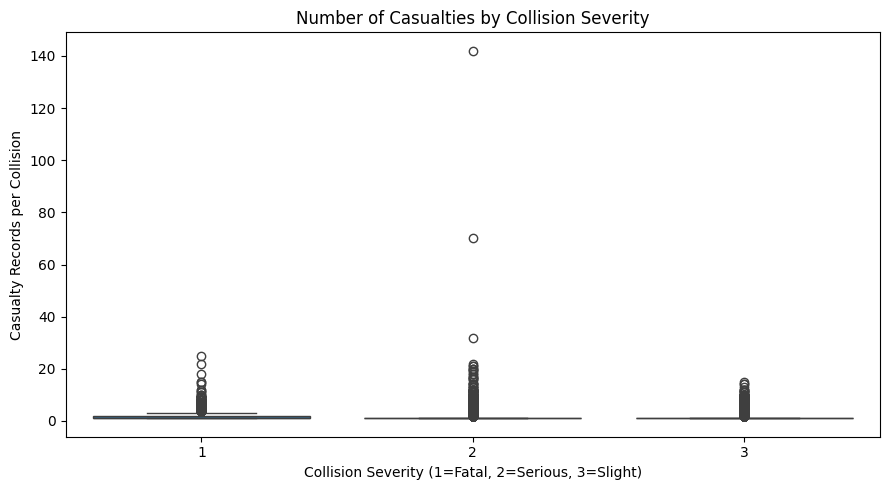

In [34]:
# EDA on Merged dataset
# 1. Collision severity versus number of casualties

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_merged,
    x="collision_severity",
    y="casualty_records"
)
plt.title("Number of Casualties by Collision Severity")
plt.xlabel("Collision Severity (1=Fatal, 2=Serious, 3=Slight)")
plt.ylabel("Casualty Records per Collision")
plt.tight_layout()
plt.show()




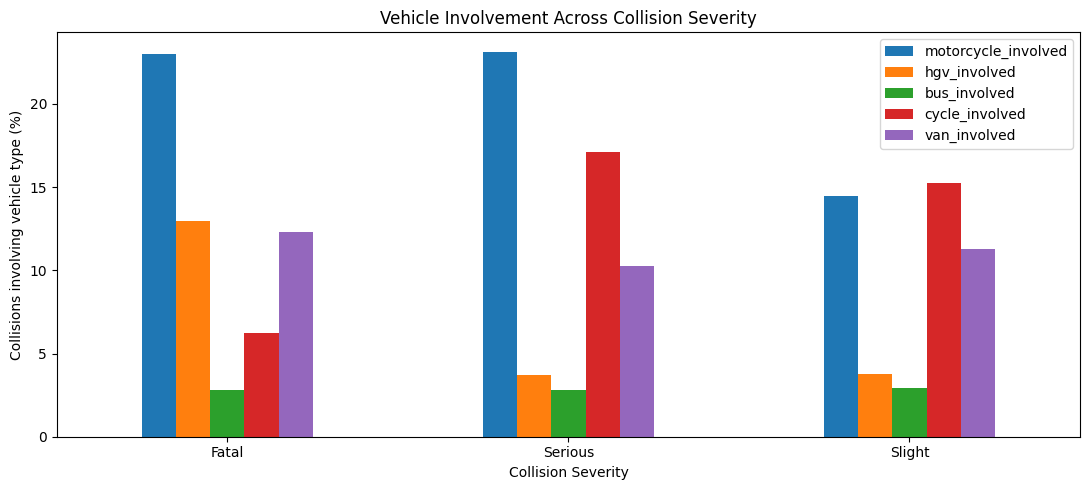

In [35]:
# 2. Severity versus involvement of different vehicle types

vehicle_flags = [
    "motorcycle_involved", "hgv_involved", "bus_involved",
    "cycle_involved", "van_involved"
]

severity_by_vehicle = df_merged.groupby(
    "collision_severity"
)[vehicle_flags].mean() * 100

severity_by_vehicle.index = severity_by_vehicle.index.map({
    1: "Fatal", 2: "Serious", 3: "Slight"
})

severity_by_vehicle.plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Vehicle Involvement Across Collision Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Collisions involving vehicle type (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




In [36]:
# 3. Severity versus pedestrian involvement

pedestrian_rates = (
    df_merged.groupby("collision_severity")["pedestrian_casualty"]
    .mean() * 100
)

print("Percentage of collisions with pedestrian casualties by severity:")
display(pedestrian_rates.to_frame("percentage"))




Percentage of collisions with pedestrian casualties by severity:


,percentage
collision_severity,
1,25.513313
2,23.023770
3,15.896150


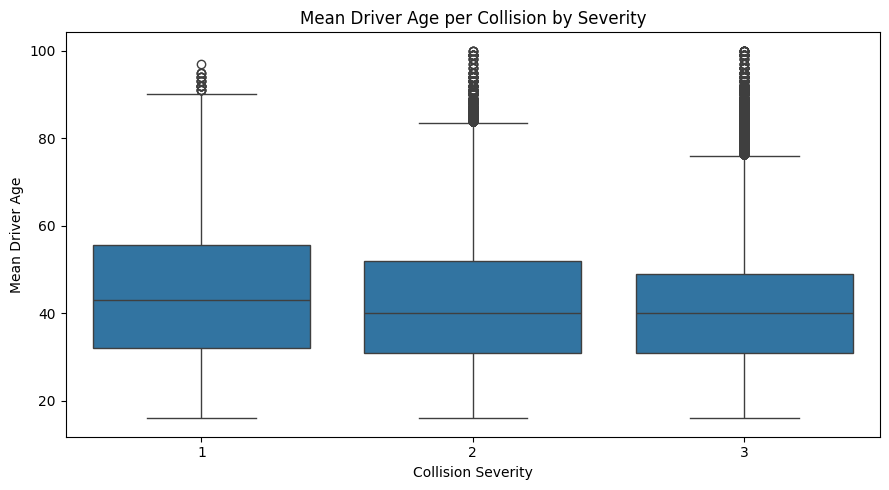

In [37]:
# 4. Driver age distribution by severity

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_merged,
    x="collision_severity",
    y="mean_driver_age"
)
plt.title("Mean Driver Age per Collision by Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Mean Driver Age")
plt.tight_layout()
plt.show()




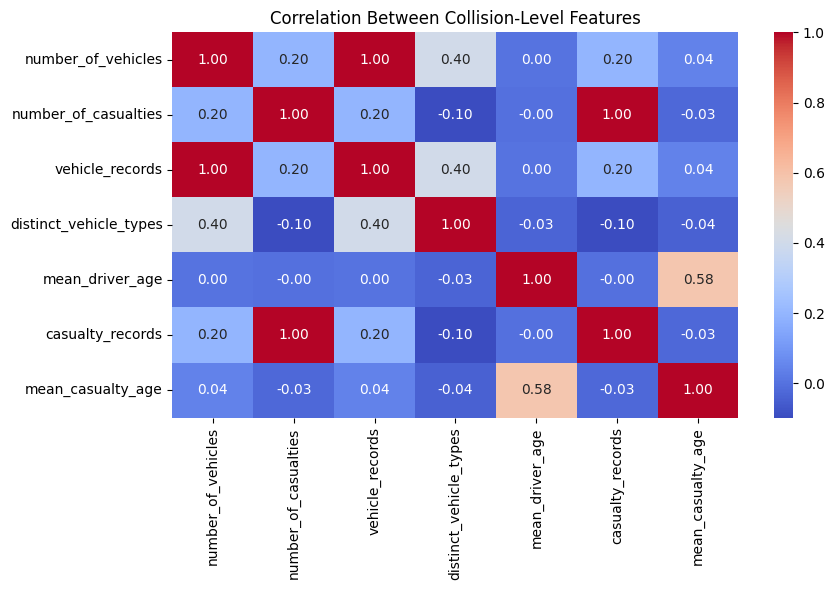

In [38]:
# 5. Correlation among selected numerical features

numeric_cols = [
    "number_of_vehicles", "number_of_casualties",
    "vehicle_records", "distinct_vehicle_types",
    "mean_driver_age", "casualty_records",
    "mean_casualty_age"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df_merged[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Collision-Level Features")
plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_5344\60234460.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


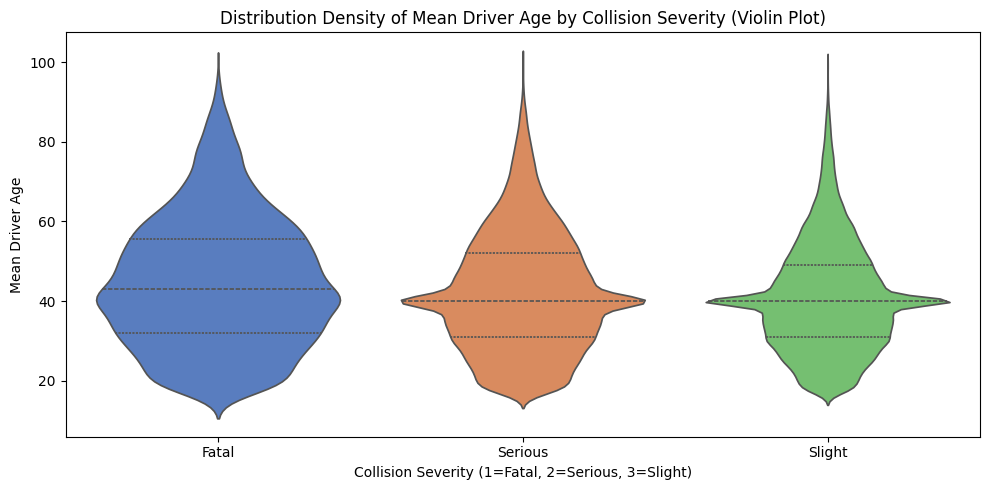

In [39]:
# Revealing Distribution Density & Tails
plt.figure(figsize=(10, 5))
sns.violinplot(
    data=df_merged,
    x="collision_severity",
    y="mean_driver_age",
    palette="muted",
    inner="quart"
)
plt.title("Distribution Density of Mean Driver Age by Collision Severity (Violin Plot)")
plt.xlabel("Collision Severity (1=Fatal, 2=Serious, 3=Slight)")
plt.ylabel("Mean Driver Age")
plt.xticks([0, 1, 2], ["Fatal", "Serious", "Slight"])
plt.tight_layout()
plt.show()

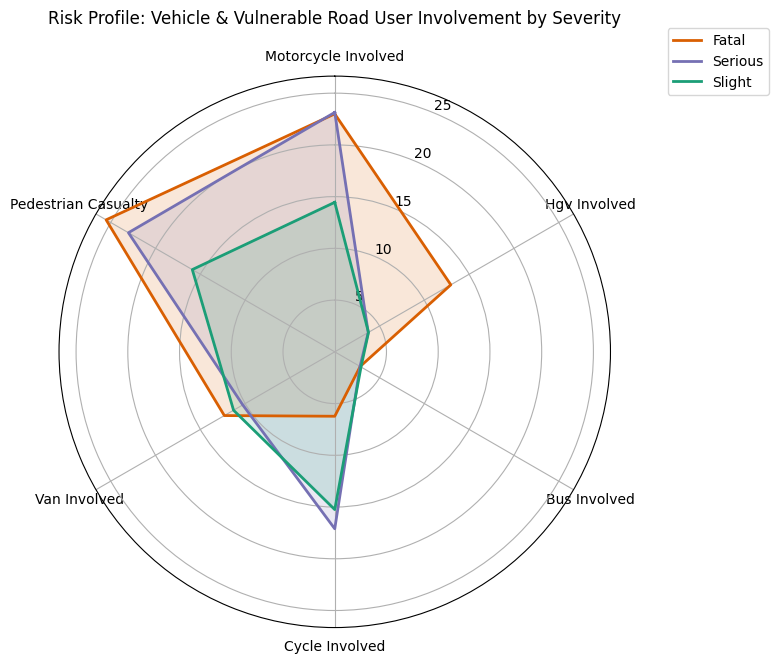

In [49]:
# 1. Define features and data
radar_features = [
    "motorcycle_involved", "hgv_involved", "bus_involved", 
    "cycle_involved", "van_involved", "pedestrian_casualty"
]

severity_profiles = df_merged.groupby("collision_severity")[radar_features].mean() * 100
severity_profiles.index = ["Fatal", "Serious", "Slight"]

labels = [f.replace("_", " ").title() for f in radar_features]
num_vars = len(labels)

# 2. Generate exact angles for the 6 categories
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False)
# Create a closed-loop version for polygon plotting (repeating the first angle at the end)
plot_angles = np.append(angles, angles[0])

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

colors = {
    "Fatal": "#d95f02", 
    "Serious": "#7570b3", 
    "Slight": "#1b9e77"
}

for severity_label, row in severity_profiles.iterrows():
    values = row.values.flatten().tolist()
    # Close the loop for values as well
    values.append(values[0])
    
    ax.plot(plot_angles, values, linewidth=2, linestyle='solid', label=severity_label, color=colors[severity_label])
    ax.fill(plot_angles, values, color=colors[severity_label], alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# 3. Explicitly map the 6 tick angles to the 6 labels
ax.set_xticks(angles)
ax.set_xticklabels(labels, fontsize=10)

ax.set_title("Risk Profile: Vehicle & Vulnerable Road User Involvement by Severity", y=1.08, fontsize=12)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

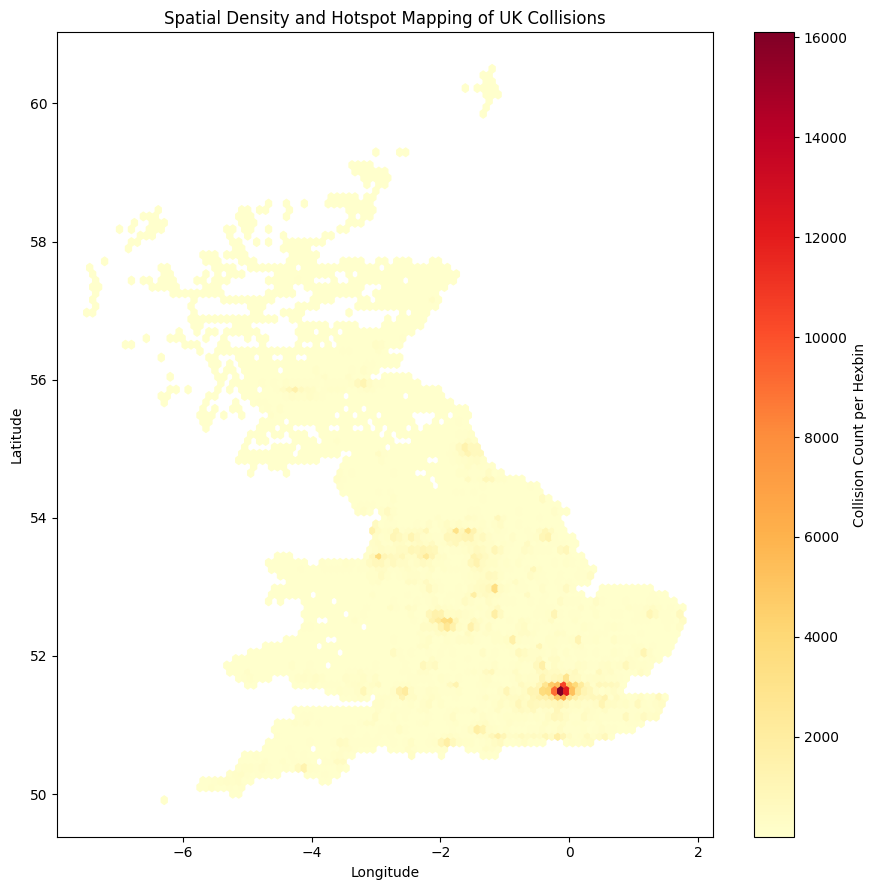

In [50]:
# Accident Density Hotspots

plt.figure(figsize=(9, 9))
plt.hexbin(
    df_merged["longitude"], 
    df_merged["latitude"], 
    gridsize=100, 
    cmap="YlOrRd", 
    mincnt=1
)
cb = plt.colorbar(label="Collision Count per Hexbin")
plt.title("Spatial Density and Hotspot Mapping of UK Collisions")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

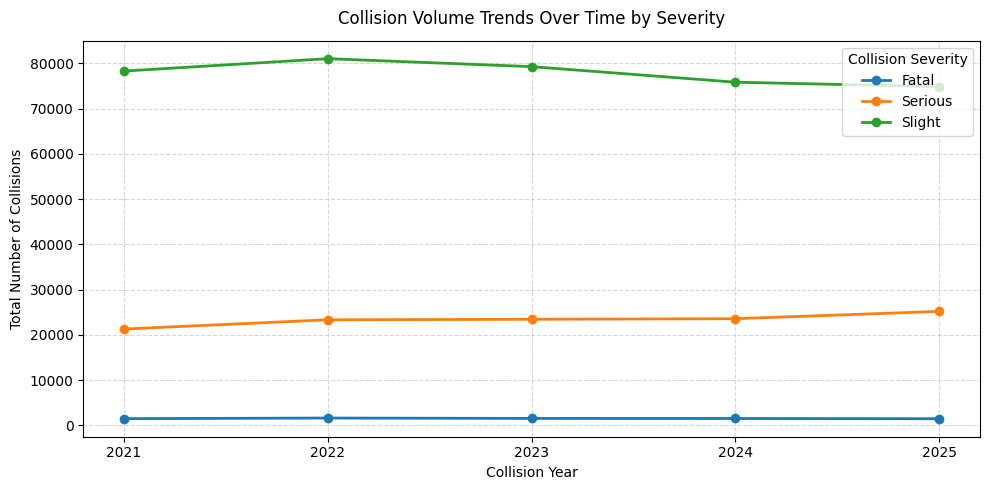

In [51]:
# Temporal Trend: Collisions over Years broken down by Severity
if "collision_year" in df_merged.columns:
    # Group by year and severity, then pivot to get severity levels as columns
    yearly_severity = df_merged.groupby(["collision_year", "collision_severity"]).size().unstack(fill_value=0)
    
    # Map severity codes to descriptive labels
    yearly_severity.columns = ["Fatal", "Serious", "Slight"]
    
    # Plotting the trend lines
    plt.figure(figsize=(10, 5))
    ax = yearly_severity.plot(kind="line", marker="o", linewidth=2, figsize=(10, 5))
    
    plt.title("Collision Volume Trends Over Time by Severity", fontsize=12, pad=12)
    plt.xlabel("Collision Year", fontsize=10)
    plt.ylabel("Total Number of Collisions", fontsize=10)
    plt.legend(title="Collision Severity", loc="upper right")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(yearly_severity.index)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'collision_year' not found in df_merged.")

Preparing data for Pattern Mining


In [58]:
import numpy as np, pandas as pd

col = collisions_df.set_index('collision_index')
veh = vehicles_df
cas = casualties_df

def m(series, mapping, name):
    # code -> 'Name=Label'; anything not in mapping (unknown) -> NaN
    return series.map(mapping).map(lambda v: f"{name}={v}" if pd.notna(v) else np.nan)

items = pd.DataFrame(index=col.index)

# ---- target ----
items['sev'] = m(col['collision_severity'], {1:'Fatal', 2:'Serious', 3:'Slight'}, 'Severity')

# ---- road / environment ----
items['speed'] = col['speed_limit'].where(col['speed_limit'] > 0).map(lambda v: f"Speed={int(v)}mph" if pd.notna(v) else np.nan)
items['light'] = m(col['light_conditions'], {1:'Daylight', 4:'Dark_streetlit', 5:'Dark_unlit', 6:'Dark_unlit'}, 'Light')
items['weather'] = m(col['weather_conditions'], {1:'Fine', 2:'Rain', 3:'Snow', 4:'HighWind', 5:'HighWind', 6:'HighWind', 7:'Fog'}, 'Weather')
items['surface'] = m(col['road_surface_conditions'], {1:'Dry', 2:'Wet', 3:'Snow_Ice', 4:'Snow_Ice', 5:'Flood'}, 'Surface')
items['area'] = m(col['urban_or_rural_area'], {1:'Urban', 2:'Rural'}, 'Area')
items['roadtype'] = m(col['road_type'], {1:'Roundabout', 2:'OneWay', 3:'DualCarriageway', 6:'SingleCarriageway', 7:'SlipRoad', 12:'OneWay_Slip'}, 'RoadType')
items['junction'] = m(col['junction_detail'], {0:'None', 1:'Roundabout', 2:'MiniRoundabout', 3:'T_Junction', 5:'SlipRoad', 6:'Crossroads', 7:'MultiArm', 8:'PrivateDrive', 9:'Other'}, 'Junction')
items['roadclass'] = m(col['first_road_class'], {1:'Motorway', 2:'A(M)', 3:'A', 4:'B', 5:'C', 6:'Unclassified'}, 'RoadClass')

# ---- time ----
hour = pd.to_numeric(col['time'].astype(str).str[:2], errors='coerce')
items['time'] = pd.cut(hour, bins=[-1, 5, 9, 15, 19, 23],
                       labels=['Night(0-5)', 'MorningPeak(6-9)', 'Midday(10-15)', 'EveningPeak(16-19)', 'LateEvening(20-23)']
                      ).astype(object).map(lambda v: f"Time={v}" if pd.notna(v) else np.nan)
items['daytype'] = col['day_of_week'].map({1:'Weekend', 7:'Weekend', 2:'Weekday', 3:'Weekday', 4:'Weekday', 5:'Weekday', 6:'Weekday'}).map(lambda v: f"Day={v}" if pd.notna(v) else np.nan)
month = pd.to_datetime(col['date'], dayfirst=True, errors='coerce').dt.month
items['season'] = month.map({12:'Winter', 1:'Winter', 2:'Winter', 3:'Spring', 4:'Spring', 5:'Spring',
                            6:'Summer', 7:'Summer', 8:'Summer', 9:'Autumn', 10:'Autumn', 11:'Autumn'}).map(lambda v: f"Season={v}" if pd.notna(v) else np.nan)

# ---- size of collision ----
items['nveh'] = col['number_of_vehicles'].clip(upper=3).map({1:'1', 2:'2', 3:'3+'}).map(lambda v: f"Vehicles={v}" if pd.notna(v) else np.nan)
items['ncas'] = col['number_of_casualties'].clip(upper=3).map({1:'1', 2:'2', 3:'3+'}).map(lambda v: f"Casualties={v}" if pd.notna(v) else np.nan)

# ---- vehicle-level -> collision-level flags (item only when True) ----
MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV        = {20, 21, 98, 113}
BUS        = {11, 108, 109}

v = veh.copy()
v['f_motorcycle'] = v['vehicle_type'].isin(MOTORCYCLE)
v['f_cycle']      = v['vehicle_type'].eq(1)
v['f_hgv']        = v['vehicle_type'].isin(HGV)
v['f_bus']        = v['vehicle_type'].isin(BUS)
v['f_van']        = v['vehicle_type'].eq(19)
v['f_young_drv']  = v['age_band_of_driver'].isin([4, 5])        # 16-25
v['f_old_drv']    = v['age_band_of_driver'].isin([10, 11])      # 66+

# Safely coerce columns to numeric to avoid type comparison errors with strings/unknowns
v['f_skid']       = pd.to_numeric(v['skidding_and_overturning'], errors='coerce').gt(0)
v['f_left_road']  = pd.to_numeric(v['vehicle_leaving_carriageway'], errors='coerce').gt(0)
v['f_hit_offroad']= pd.to_numeric(v['hit_object_off_carriageway'], errors='coerce').gt(0)

vflags = v.groupby('collision_index')[[c for c in v.columns if c.startswith('f_')]].any()
vnames = {'f_motorcycle':'Motorcycle_involved', 'f_cycle':'Cycle_involved', 'f_hgv':'HGV_involved', 'f_bus':'Bus_involved',
          'f_van':'Van_involved', 'f_young_drv':'YoungDriver(16-25)', 'f_old_drv':'OlderDriver(66+)',
          'f_skid':'Skid_or_Overturn', 'f_left_road':'LeftCarriageway', 'f_hit_offroad':'HitObjectOffRoad'}

# ---- casualty-level -> collision-level flags ----
c2 = cas.copy()
c2['f_ped_cas']   = c2['casualty_class'].eq(3)
c2['f_child_cas'] = c2['age_band_of_casualty'].isin([1, 2, 3])   # 0-15
c2['f_old_cas']   = c2['age_band_of_casualty'].isin([10, 11])    # 66+
cflags = c2.groupby('collision_index')[['f_ped_cas', 'f_child_cas', 'f_old_cas']].any()
cnames = {'f_ped_cas':'Pedestrian_casualty', 'f_child_cas':'Child_casualty', 'f_old_cas':'Elderly_casualty'}

# ---- one-hot ----
cat_part = pd.get_dummies(items, prefix='', prefix_sep='', dtype=bool)
flag_part = (vflags.rename(columns=vnames).reindex(col.index, fill_value=False)
             .join(cflags.rename(columns=cnames).reindex(col.index, fill_value=False)))
basket = pd.concat([cat_part, flag_part], axis=1).astype(bool)

# drop ultra-rare items (<0.1%) - they can never be frequent anyway and just slow Apriori
keep = basket.columns[basket.mean() >= 0.001]
basket = basket[keep]
N = len(basket)
print("transactions:", N, "| items:", basket.shape[1], "| avg items per transaction:", round(basket.sum(axis=1).mean(), 1))
print(basket.mean().sort_values(ascending=False).round(3).to_string())

transactions: 513708 | items: 65 | avg items per transaction: 15.3
Casualties=1                  0.815
Weather=Fine                  0.805
Severity=Slight               0.758
Day=Weekday                   0.750
Surface=Dry                   0.728
RoadType=SingleCarriageway    0.726
Light=Daylight                0.717
Area=Urban                    0.672
Vehicles=2                    0.619
Speed=30mph                   0.520
Junction=None                 0.491
RoadClass=A                   0.440
Time=Midday(10-15)            0.359
RoadClass=Unclassified        0.359
Area=Rural                    0.328
Time=EveningPeak(16-19)       0.295
Vehicles=1                    0.293
YoungDriver(16-25)            0.269
Season=Autumn                 0.268
Season=Summer                 0.261
LeftCarriageway               0.253
Skid_or_Overturn              0.251
Day=Weekend                   0.250
Season=Spring                 0.244
Surface=Wet                   0.235
Severity=Serious              0.2

In [59]:

print("TRANSACTION DATASET VALIDATION")
print("-" * 45)

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Missing cells:", basket.isna().sum().sum())
print("Duplicate collision IDs:", basket.index.duplicated().sum())
print("Duplicate item names:", basket.columns.duplicated().sum())
print("Empty transactions:", (~basket.any(axis=1)).sum())

print("\nMost frequent items (% of transactions):")
display(
    (basket.mean() * 100)
    .sort_values(ascending=False)
    .head(20)
    .round(2)
    .to_frame("support_percent")
)

print("\nTransactions as item lists:")
transactions = [
    basket.columns[row].tolist()
    for row in basket.to_numpy(dtype=bool)
]

for i, transaction in enumerate(transactions[:10], start=1):
    print(f"T{i}: {transaction}")


TRANSACTION DATASET VALIDATION
---------------------------------------------
Transactions: 513708
Items: 65
Missing cells: 0
Duplicate collision IDs: 0
Duplicate item names: 0
Empty transactions: 0

Most frequent items (% of transactions):


,support_percent
Casualties=1,81.51
Weather=Fine,80.51
Severity=Slight,75.80
Day=Weekday,75.02
Surface=Dry,72.85
RoadType=SingleCarriageway,72.61
Light=Daylight,71.67
Area=Urban,67.22
Vehicles=2,61.88
Speed=30mph,52.03



Transactions as item lists:
T1: ['Severity=Serious', 'Speed=30mph', 'Light=Daylight', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'Junction=None', 'RoadClass=Unclassified', 'Time=EveningPeak(16-19)', 'Day=Weekday', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'OlderDriver(66+)']
T2: ['Severity=Serious', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'RoadClass=A', 'Time=EveningPeak(16-19)', 'Day=Weekend', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'YoungDriver(16-25)']
T3: ['Severity=Slight', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'RoadClass=A', 'Time=LateEvening(20-23)', 'Day=Weekend', 'Season=Summer', 'Vehicles=2', 'Casualties=3+', 'Van_involved', 'Child_casualty']
T4: ['Severity=Slight', 'Speed=60mph', 'Light=Daylight', 'Weather=Fine', 'Surface=Dry', 'Area=Rural', 'RoadT

## RUN ARM Algorithms
1. Apriori
2. FP Growth
3. Dynamic Itemset Counting

In [60]:
%pip -q install mlxtend


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\user\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [61]:

import time
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth

# Use your existing Boolean transaction table
assert isinstance(basket, pd.DataFrame), "basket must be a DataFrame"
assert basket.shape[0] > 0, "basket has no transactions"
assert basket.shape[1] > 0, "basket has no items"
assert basket.index.is_unique, "basket must have unique collision IDs"
assert not basket.isna().any().any(), "basket contains missing values"

# Ensure Boolean format
basket = basket.astype(bool)

MIN_SUPPORT = 0.04
MIN_SUPPORT_COUNT = math.ceil(MIN_SUPPORT * len(basket))

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Minimum support:", MIN_SUPPORT)
print("Minimum support count:", MIN_SUPPORT_COUNT)
print("Average items per transaction:",
      round(basket.sum(axis=1).mean(), 2))
print("Maximum possible frequent itemset size:", basket.shape[1])

Transactions: 513708
Items: 65
Minimum support: 0.04
Minimum support count: 20549
Average items per transaction: 15.34
Maximum possible frequent itemset size: 65


Run Apriori

In [62]:

def run_apriori(transactions, min_support):
    start = time.perf_counter()

    result = apriori(
        transactions,
        min_support=min_support,
        use_colnames=True,
        low_memory=True
    )

    elapsed = time.perf_counter() - start

    if not result.empty:
        result["itemset_size"] = result["itemsets"].apply(len)
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    return result, elapsed


apriori_result, apriori_time = run_apriori(basket, MIN_SUPPORT)

print("Apriori runtime:", round(apriori_time, 4), "seconds")
print("Frequent itemsets:", len(apriori_result))

display(apriori_result.head(30))


Apriori runtime: 356.8695 seconds
Frequent itemsets: 30406


,support,itemsets,itemset_size
0,0.815090,(Casualties=1),1
1,0.805072,(Weather=Fine),1
2,0.757962,(Severity=Slight),1
3,0.750169,(Day=Weekday),1
4,0.728461,(Surface=Dry),1
5,0.726086,(RoadType=SingleCarriageway),1
6,0.716650,(Light=Daylight),1
7,0.672166,(Area=Urban),1
8,0.618772,(Vehicles=2),1
9,0.520307,(Speed=30mph),1


In [63]:
# Save Apriori results to Google Drive
apriori_result.to_pickle(
    "./apriori_result.pkl"
)

print("Apriori results saved!")

Apriori results saved!


In [24]:
if not apriori_result.empty:
    itemset_lengths = apriori_result["itemsets"].apply(len)

    print("Total Frequent Itemsets:", len(apriori_result))
    print("Maximum Length of FI:", itemset_lengths.max())
    print("Minimum Length of FI:", itemset_lengths.min())
else:
    print("No frequent itemsets found.")

print("\nFrequent Itemsets by Length:")
print(
    apriori_result["itemsets"]
    .apply(len)
    .value_counts()
    .sort_index()
)

Total Frequent Itemsets: 30406
Maximum Length of FI: 10
Minimum Length of FI: 1

Frequent Itemsets by Length:
itemsets
1       53
2      680
3     3261
4     7065
5     8499
6     6516
7     3243
8      940
9      141
10       8
Name: count, dtype: int64


Run FP Growth

In [25]:
def run_fpgrowth(transactions, min_support, max_len=3):
    start = time.perf_counter()

    result = fpgrowth(
        transactions,
        min_support=min_support,
        use_colnames=True,
        max_len=max_len
    )

    elapsed = time.perf_counter() - start

    if not result.empty:
        result["itemset_size"] = result["itemsets"].apply(len)
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    return result, elapsed


fp_result, fp_time = run_fpgrowth(
    basket,
    MIN_SUPPORT,
    max_len=10
)

print("FP-Growth runtime:", round(fp_time, 4), "seconds")
print("Frequent itemsets:", len(fp_result))

display(fp_result.head(30))

FP-Growth runtime: 174.7856 seconds
Frequent itemsets: 30406


,support,itemsets,itemset_size
0,0.815088,frozenset({Casualties=1}),1
1,0.805043,frozenset({Weather=Fine}),1
2,0.757957,frozenset({Severity=Slight}),1
3,0.750173,frozenset({Day=Weekday}),1
4,0.728433,frozenset({Surface=Dry}),1
5,0.726086,frozenset({RoadType=SingleCarriageway}),1
6,0.716604,frozenset({Light=Daylight}),1
7,0.672147,frozenset({Area=Urban}),1
8,0.618755,frozenset({Vehicles=2}),1
9,0.520292,frozenset({Speed=30mph}),1


In [29]:
# Save Apriori results to Google Drive
fp_result.to_pickle(
    "./fp_result.pkl"
)

print("FP Growth results saved!")

FP Growth results saved!


Run DIC

In [30]:

import time
import math
import itertools
import pandas as pd
import numpy as np


def run_dic_baseline(
    transactions,
    min_support=0.04,
    block_size=25000,
    max_len=10
):
    """
    Optimized DIC-style frequent-itemset miner using vertical bitsets.

    Uses exact support counts and Apriori subset pruning.
    max_len limits the largest itemset generated.

    Note: This is a level-wise, bitset-optimized DIC-style baseline,
    not canonical incremental DIC.
    block_size is retained for API compatibility but is not used
    by this vertical-bitset implementation.
    """
    start = time.perf_counter()

    # Convert the basket to a Boolean matrix.
    matrix = transactions.to_numpy(dtype=bool, copy=True)
    n, n_items = matrix.shape

    columns = list(transactions.columns)

    if n == 0 or n_items == 0:
        empty = pd.DataFrame(
            columns=["support", "itemsets", "itemset_size"]
        )
        return empty, time.perf_counter() - start, 0

    if not 0 <= min_support <= 1:
        raise ValueError("min_support must be between 0 and 1.")

    if max_len < 1:
        raise ValueError("max_len must be at least 1.")

    min_count = math.ceil(min_support * n)
    max_size = min(max_len, n_items)

    # Each item is represented by a bitset indicating the
    # transactions in which it occurs.
    item_masks = {}

    for j, item in enumerate(columns):
        packed = np.packbits(matrix[:, j], bitorder="little")
        item_masks[item] = int.from_bytes(
            packed.tobytes(), byteorder="little"
        )

    # Single-item support counts.
    frequent = {}
    masks = {}
    candidates_evaluated = 0

    for item in columns:
        itemset = frozenset([item])
        mask = item_masks[item]
        count = mask.bit_count()
        candidates_evaluated += 1

        if count >= min_count:
            frequent[itemset] = count
            masks[itemset] = mask

    # Generate larger frequent itemsets level by level.
    previous_level = list(frequent.keys())
    level = 2

    while previous_level and level <= max_size:
        previous_level = sorted(
            previous_level,
            key=lambda s: tuple(
                sorted(columns.index(x) for x in s)
            )
        )

        previous_set = set(previous_level)
        candidates = set()

        # Join frequent (level-1)-itemsets.
        for i in range(len(previous_level)):
            for j in range(i + 1, len(previous_level)):
                union = previous_level[i] | previous_level[j]

                if len(union) != level:
                    continue

                # Every immediate subset must be frequent.
                if all(
                    frozenset(subset) in previous_set
                    for subset in itertools.combinations(union, level - 1)
                ):
                    candidates.add(frozenset(union))

        if not candidates:
            break

        current_level = []

        for candidate in candidates:
            # Intersect the bitsets of its items.
            items = iter(candidate)
            mask = item_masks[next(items)]

            for item in items:
                mask &= item_masks[item]

                if mask == 0:
                    break

            count = mask.bit_count()
            candidates_evaluated += 1

            if count >= min_count:
                frequent[candidate] = count
                masks[candidate] = mask
                current_level.append(candidate)

        previous_level = current_level
        level += 1

    # Format results.
    rows = [
        {
            "support": count / n,
            "itemsets": itemset,
            "itemset_size": len(itemset)
        }
        for itemset, count in frequent.items()
        if len(itemset) <= max_len
    ]

    result = pd.DataFrame(
        rows,
        columns=["support", "itemsets", "itemset_size"]
    )

    if not result.empty:
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    elapsed = time.perf_counter() - start

    return result, elapsed, candidates_evaluated


# Run on the 500,000-record transaction dataset
dic_result, dic_time, dic_candidates = run_dic_baseline(
    basket,
    min_support=MIN_SUPPORT,
    block_size=25000,
    max_len=10
)

print("Optimized DIC-style runtime:", round(dic_time, 4), "seconds")
print("Frequent itemsets:", len(dic_result))
print(
    "Maximum FI length:",
    dic_result["itemset_size"].max() if not dic_result.empty else 0
)
print("Candidates evaluated:", dic_candidates)

display(dic_result.head(30))


Optimized DIC-style runtime: 254.8067 seconds
Frequent itemsets: 30406
Maximum FI length: 10
Candidates evaluated: 42049


,support,itemsets,itemset_size
0,0.815088,frozenset({Casualties=1}),1
1,0.805043,frozenset({Weather=Fine}),1
2,0.757957,frozenset({Severity=Slight}),1
3,0.750173,frozenset({Day=Weekday}),1
4,0.728433,frozenset({Surface=Dry}),1
5,0.726086,frozenset({RoadType=SingleCarriageway}),1
6,0.716604,frozenset({Light=Daylight}),1
7,0.672147,frozenset({Area=Urban}),1
8,0.618755,frozenset({Vehicles=2}),1
9,0.520292,frozenset({Speed=30mph}),1


Compare FI Results

In [31]:

def itemset_support_map(result):
    return {
        frozenset(row.itemsets): float(row.support)
        for row in result.itertuples()
    }


a_map = itemset_support_map(apriori_result)
f_map = itemset_support_map(fp_result)
d_map = itemset_support_map(dic_result)

print("Apriori and FP-Growth have identical itemsets:",
      set(a_map) == set(f_map))

print("Apriori and DIC have identical itemsets:",
      set(a_map) == set(d_map))

if set(a_map) == set(f_map):
    print("Maximum support difference (Apriori vs FP-Growth):",
          max(abs(a_map[k] - f_map[k]) for k in a_map))

if set(a_map) == set(d_map):
    print("Maximum support difference (Apriori vs DIC):",
          max(abs(a_map[k] - d_map[k]) for k in a_map))

# Show itemsets discovered by one algorithm but not another
print("\nItemsets only in Apriori:", len(set(a_map) - set(f_map)))
print("Itemsets only in FP-Growth:", len(set(f_map) - set(a_map)))
print("Itemsets only in DIC:", len(set(d_map) - set(a_map)))


Apriori and FP-Growth have identical itemsets: True
Apriori and DIC have identical itemsets: True
Maximum support difference (Apriori vs FP-Growth): 0.0
Maximum support difference (Apriori vs DIC): 0.0

Itemsets only in Apriori: 0
Itemsets only in FP-Growth: 0
Itemsets only in DIC: 0


In [32]:

results = {
    "Apriori": (apriori_result, apriori_time),
    "FP-Growth": (fp_result, fp_time),
    "DIC prototype": (dic_result, dic_time)
}

comparison_rows = []

for algorithm, (result, elapsed) in results.items():
    sizes = (
        result["itemset_size"].value_counts().sort_index()
        if not result.empty else pd.Series(dtype=int)
    )

    comparison_rows.append({
        "Algorithm": algorithm,
        "Runtime (seconds)": elapsed,
        "Frequent itemsets": len(result),
        "Frequent 1-itemsets": int(sizes.get(1, 0)),
        "Frequent 2-itemsets": int(sizes.get(2, 0)),
        "Frequent 3+-itemsets": int(sizes[sizes.index >= 3].sum())
            if len(sizes) else 0,
        "Longest itemset": int(result["itemset_size"].max())
            if not result.empty else 0
    })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        "Runtime (seconds)": "{:.4f}"
    })
)


AttributeError: The '.style' accessor requires jinja2

Execution Time Comparision

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Runtime (seconds)"]
)

plt.ylabel("Execution time (seconds)")
plt.title("Execution Time Comparison: ARM Algorithms")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


No of FI

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Frequent itemsets"]
)

plt.ylabel("Number of frequent itemsets")
plt.title("Frequent Itemset Count by Algorithm")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Itemset size distribution

In [ ]:

size_rows = []

for algorithm, (result, _) in results.items():
    if result.empty:
        continue

    counts = result["itemset_size"].value_counts().sort_index()

    for size, count in counts.items():
        size_rows.append({
            "Algorithm": algorithm,
            "Itemset size": size,
            "Count": count
        })

size_df = pd.DataFrame(size_rows)

if not size_df.empty:
    size_pivot = size_df.pivot(
        index="Itemset size",
        columns="Algorithm",
        values="Count"
    ).fillna(0)

    size_pivot.plot(
        kind="bar",
        figsize=(11, 5)
    )

    plt.ylabel("Frequent itemset count")
    plt.title("Frequent Itemsets by Size")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No frequent itemsets found.")


Runtime vs Min-support

In [ ]:

support_levels = [0.20, 0.15, 0.10]

support_rows = []

for support in support_levels:
    print(f"Running algorithms at minimum support = {support:.0%}")

    for algorithm, function in [
        ("Apriori", run_apriori),
        ("FP-Growth", run_fpgrowth)
    ]:
        result, elapsed = function(basket, support)

        support_rows.append({
            "Minimum support": support,
            "Algorithm": algorithm,
            "Runtime (seconds)": elapsed,
            "Frequent itemsets": len(result)
        })

support_comparison = pd.DataFrame(support_rows)

display(support_comparison)

plt.figure(figsize=(9, 5))

for algorithm, group in support_comparison.groupby("Algorithm"):
    plt.plot(
        group["Minimum support"] * 100,
        group["Runtime (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Minimum support (%)")
plt.ylabel("Execution time (seconds)")
plt.title("Runtime vs Minimum Support")
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

In [ ]:

fastest = comparison_df.loc[
    comparison_df["Runtime (seconds)"].idxmin()
]

print("PHASE 1: EXPERIMENTAL INFERENCES")
print("=" * 55)

print(
    f"Fastest measured implementation: {fastest['Algorithm']} "
    f"({fastest['Runtime (seconds)']:.4f} seconds)."
)

counts = comparison_df["Frequent itemsets"]

if counts.nunique() == 1:
    print("All three algorithms returned the same number of frequent itemsets.")
else:
    print("The algorithms returned different itemset counts.")
    print("Check itemset equality and support calculations before interpreting.")

if len(support_comparison):
    for algorithm, group in support_comparison.groupby("Algorithm"):
        ordered = group.sort_values("Minimum support")
        if len(ordered) >= 2:
            first = ordered.iloc[0]
            last = ordered.iloc[-1]

            print(
                f"{algorithm}: at {first['Minimum support']:.0%} support, "
                f"{int(first['Frequent itemsets'])} itemsets; "
                f"at {last['Minimum support']:.0%}, "
                f"{int(last['Frequent itemsets'])} itemsets."
            )

print("\nInterpretation:")
print("- Lower support usually increases the number of frequent itemsets.")
print("- Runtime depends on both the algorithm and dataset characteristics.")
print("- Compare exact itemsets and supports before comparing performance.")
print("- The DIC prototype runtime is not a canonical DIC benchmark.")

Generate Association Rules

In [ ]:

from mlxtend.frequent_patterns import association_rules

MIN_CONFIDENCE = 0.70

def generate_rules(frequent_itemsets, min_confidence=0.70):
    if frequent_itemsets.empty:
        return pd.DataFrame()

    # association_rules requires support and itemsets columns
    rules = association_rules(
        frequent_itemsets[["support", "itemsets"]],
        metric="confidence",
        min_threshold=min_confidence
    )

    if rules.empty:
        return rules

    # Keep useful metrics and readable item names
    rules["antecedents"] = rules["antecedents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )
    rules["consequents"] = rules["consequents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )

    columns = [
        "antecedents", "consequents",
        "antecedent support", "consequent support",
        "support", "confidence", "lift",
        "leverage", "conviction"
    ]

    return rules[columns].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)


apriori_rules = generate_rules(apriori_result, MIN_CONFIDENCE)
fp_rules = generate_rules(fp_result, MIN_CONFIDENCE)
dic_rules = generate_rules(dic_result, MIN_CONFIDENCE)

print("Apriori rules:", len(apriori_rules))
print("FP-Growth rules:", len(fp_rules))
print("DIC rules:", len(dic_rules))

print("\nTop Apriori rules:")
display(apriori_rules.head(20))

print("\nTop FP-Growth rules:")
display(fp_rules.head(20))

print("\nTop DIC rules:")
display(dic_rules.head(20))


Compare Association Rules

In [ ]:

rule_results = {
    "Apriori": apriori_rules,
    "FP-Growth": fp_rules,
    "DIC": dic_rules
}

rule_comparison = []

for algorithm, rules in rule_results.items():
    if rules.empty:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": 0,
            "Mean confidence": np.nan,
            "Mean lift": np.nan,
            "Maximum lift": np.nan,
            "Rules with lift > 1": 0
        })
    else:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": len(rules),
            "Mean confidence": rules["confidence"].mean(),
            "Mean lift": rules["lift"].mean(),
            "Maximum lift": rules["lift"].max(),
            "Rules with lift > 1": (rules["lift"] > 1).sum()
        })

rule_comparison_df = pd.DataFrame(rule_comparison)

display(
    rule_comparison_df.style.format({
        "Mean confidence": "{:.3f}",
        "Mean lift": "{:.3f}",
        "Maximum lift": "{:.3f}"
    })
)

Plot Association Rule Metrics

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("confidence", "Confidence"),
    ("lift", "Lift"),
    ("support", "Support")
]

for ax, (metric, title) in zip(axes, metrics):
    values = [
        rules[metric].dropna().values
        for rules in rule_results.values()
        if not rules.empty
    ]

    labels = [
        name for name, rules in rule_results.items()
        if not rules.empty
    ]

    if values:
        ax.boxplot(values, tick_labels=labels)
        ax.set_title(f"Rule {title} Distribution")
        ax.set_ylabel(title)
        ax.tick_params(axis="x", rotation=20)
    else:
        ax.set_title(f"No rules available for {title}")

plt.tight_layout()
plt.show()


Extract rules involving severity

In [10]:

def severity_rules(rules):
    if rules.empty:
        return pd.DataFrame()

    return rules[
        rules["consequents"].str.contains(
            r"Severity=(Fatal|Serious)",
            regex=True,
            na=False
        )
    ].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)


print("Apriori severity rules:")
display(severity_rules(apriori_rules).head(20))

print("FP-Growth severity rules:")
display(severity_rules(fp_rules).head(20))

print("DIC severity rules:")
display(severity_rules(dic_rules).head(20))


Apriori severity rules:


NameError: name 'apriori_rules' is not defined